First five records:
  buying  maint doors persons lug_boot safety  class
0  vhigh  vhigh     2       2    small    low  unacc
1  vhigh  vhigh     2       2    small    med  unacc
2  vhigh  vhigh     2       2    small   high  unacc
3  vhigh  vhigh     2       2      med    low  unacc
4  vhigh  vhigh     2       2      med    med  unacc

Dataset shape: (1728, 7)

Accuracy: 98.27 %

Classification Report:
              precision    recall  f1-score   support

         acc       0.97      0.95      0.96        77
        good       0.93      0.93      0.93        14
       unacc       0.99      1.00      0.99       242
       vgood       1.00      0.92      0.96        13

    accuracy                           0.98       346
   macro avg       0.97      0.95      0.96       346
weighted avg       0.98      0.98      0.98       346



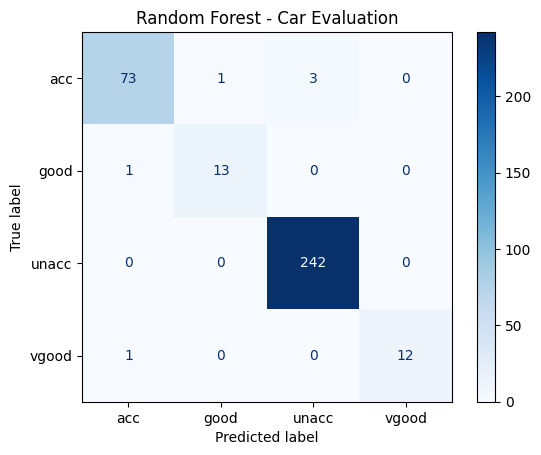

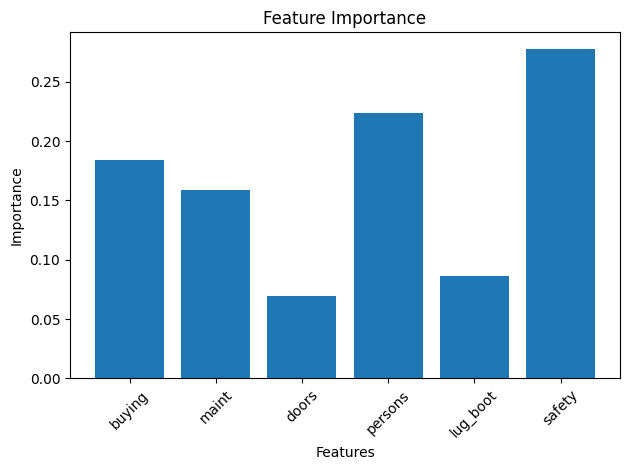

In [1]:
#5.random_forest_car_safety.ipynb
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay

# Load dataset
columns = [
    "buying", "maint", "doors", "persons",
    "lug_boot", "safety", "class"
]

df = pd.read_csv("car_evaluation.csv", header=None, names=columns)

print("First five records:")
print(df.head())
print("\nDataset shape:", df.shape)

# Encode categorical values
encoders = {}

for col in df.columns:
    encoders[col] = LabelEncoder()
    df[col] = encoders[col].fit_transform(df[col])

# Separate features and target
X = df.drop("class", axis=1)
y = df["class"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train Random Forest model
model = RandomForestClassifier(
    n_estimators=100, random_state=42
)
model.fit(X_train, y_train)

# Predict results
y_pred = model.predict(X_test)

# Evaluate model
print("\nAccuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    labels=range(len(encoders["class"].classes_)),
    target_names=encoders["class"].classes_,
    zero_division=0
))

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=encoders["class"].classes_,
    cmap="Blues"
)
plt.title("Random Forest - Car Evaluation")
plt.show()

# Feature importance
plt.bar(X.columns, model.feature_importances_)
plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Feature Importance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()